## H3 — Educación, competencias cognitivas y perspectivas laborales en la era de la inteligencia artificial

**Pregunta de investigación:**

En la era de la inteligencia artificial, ¿qué es más importante para las perspectivas laborales de una persona: el nivel de educación formal o sus competencias cognitivas reales?

**Objetivo del análisis:**

Explorar la relación entre el nivel educativo, las competencias cognitivas (literacy y numeracy) y los resultados laborales de la población adulta en España, utilizando datos de OECD PIAAC Cycle 2.

El objetivo es comprobar si las competencias cognitivas pueden aportar información adicional sobre las perspectivas laborales más allá del nivel de educación formal.

**Nota:** Esta línea de investigación es provisional. La hipótesis se formulará después de comprobar las variables disponibles en el dataset.

H3 — Educación, competencias cognitivas y perspectivas laborales

1. Carga de datos y distribución de variables

Código: importación de pandas, matplotlib y seaborn; carga del dataset CSV.

¿Qué hacemos?

Cargamos los datos de OECD PIAAC Cycle 2 correspondientes a España. Visualizamos la distribución de las variables EDLEVEL3 (nivel educativo) y PAIDWORK5 (situación laboral).

¿Para qué?

Conocer la estructura de la muestra y observar cómo se distribuyen las personas según su nivel educativo y situación laboral.

/var/folders/d2/3d1qzjt10ps6gfm7slsdgk480000gn/T/ipykernel_6258/4198652861.py:7: DtypeWarning: Columns (2167: SUBJSTATUS_BQDI, 2168: BIRTHCNTRY_BQDI, 2170: EDU_BQDI_C) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../Data/raw/datos_educacion_habilidades_empleo_espana.csv", sep=";")


Distribución del nivel educativo (EDLEVEL3):
EDLEVEL3
3    2387
1    2025
2    1375
.      84
Name: count, dtype: int64

Distribución de PAIDWORK5:
PAIDWORK5
1     4331
0      861
.u     595
.       84
Name: count, dtype: int64


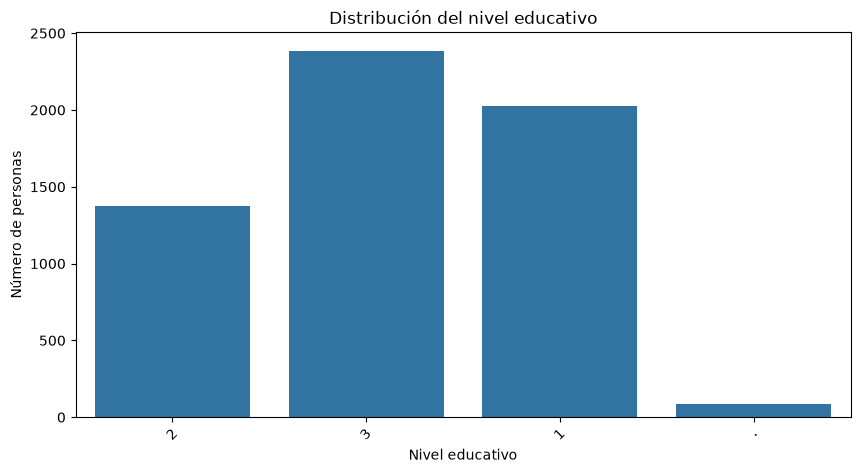

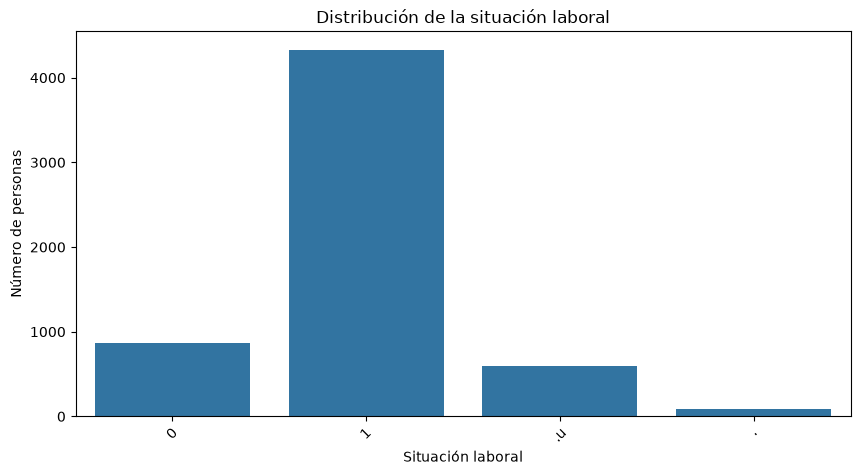

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar dataset

df = pd.read_csv("../Data/raw/datos_educacion_habilidades_empleo_espana.csv", sep=";")

# Distribución del nivel educativo
print("Distribución del nivel educativo (EDLEVEL3):")
print(df["EDLEVEL3"].value_counts(dropna=False))

# Distribución de la situación laboral
print("\nDistribución de PAIDWORK5:")
print(df["PAIDWORK5"].value_counts(dropna=False))

# Visualización del nivel educativo
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="EDLEVEL3")
plt.title("Distribución del nivel educativo")
plt.xlabel("Nivel educativo")
plt.ylabel("Número de personas")
plt.xticks(rotation=45)
plt.show()

# Visualización de la situación laboral
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="PAIDWORK5")
plt.title("Distribución de la situación laboral")
plt.xlabel("Situación laboral")
plt.ylabel("Número de personas")
plt.xticks(rotation=45)
plt.show()

2. Análisis de la relación entre educación y empleo

Código: pd.crosstab().

¿Qué hacemos?

Calculamos la distribución porcentual de la situación laboral dentro de cada categoría de nivel educativo.

¿Para qué?

Explorar si la proporción de personas en la categoría laboral 1 aumenta según el nivel educativo.

In [2]:
# Relación entre nivel educativo y situación laboral

tabla = pd.crosstab(
    df["EDLEVEL3"],
    df["PAIDWORK5"],
    normalize="index"
) * 100

print(tabla.round(2))

PAIDWORK5      .     .u      0      1
EDLEVEL3                             
.          100.0   0.00   0.00   0.00
1            0.0  11.46  24.00  64.54
2            0.0  12.51  17.24  70.25
3            0.0   8.00   5.78  86.22


3. Cálculo de las competencias cognitivas

Código: cálculo de literacy_mean y numeracy_mean.

¿Qué hacemos?

Calculamos los promedios de las variables PVLIT1–PVLIT10 y PVNUM1–PVNUM10 para obtener indicadores exploratorios de competencias cognitivas.

Literacy: competencias de comprensión y uso de información escrita.

Numeracy: competencias matemáticas.

¿Para qué?

Obtener indicadores que permitan comparar las competencias cognitivas entre grupos educativos y laborales.

Nota metodológica: el promedio de plausible values se utiliza aquí con fines exploratorios, no como estimación oficial de OECD.

In [3]:
# Relación entre competencias cognitivas, educación y empleo

# Seleccionar variables de literacy y numeracy
literacy_cols = [f"PVLIT{i}" for i in range(1, 11)]
numeracy_cols = [f"PVNUM{i}" for i in range(1, 11)]

# Convertir variables a formato numérico
df[literacy_cols + numeracy_cols] = df[literacy_cols + numeracy_cols].apply(
    pd.to_numeric, errors="coerce"
)

# Calcular promedio de competencias cognitivas
df["literacy_mean"] = df[literacy_cols].mean(axis=1)
df["numeracy_mean"] = df[numeracy_cols].mean(axis=1)

# Comparar competencias según educación y situación laboral
tabla_competencias = df.groupby(
    ["EDLEVEL3", "PAIDWORK5"]
)[["literacy_mean", "numeracy_mean"]].mean()

print(tabla_competencias.round(2))

                    literacy_mean  numeracy_mean
EDLEVEL3 PAIDWORK5                              
.        .                 167.73         154.93
1        .u                220.00         218.08
         0                 219.68         219.48
         1                 229.14         229.79
2        .u                249.35         249.07
         0                 250.01         252.52
         1                 251.05         256.00
3        .u                268.52         268.86
         0                 261.58         265.37
         1                 273.83         277.90


/var/folders/d2/3d1qzjt10ps6gfm7slsdgk480000gn/T/ipykernel_6258/2139136764.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["literacy_mean"] = df[literacy_cols].mean(axis=1)
/var/folders/d2/3d1qzjt10ps6gfm7slsdgk480000gn/T/ipykernel_6258/2139136764.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["numeracy_mean"] = df[numeracy_cols].mean(axis=1)


4. Comparación de competencias según educación y empleo

Código: groupby() y cálculo de medias.

¿Qué hacemos?

Calculamos los promedios de Literacy y Numeracy para cada combinación de nivel educativo y situación laboral.

¿Para qué?

Comparar las competencias cognitivas entre personas de la misma categoría educativa, pero con distinta situación laboral.

In [4]:
# Diferencias en competencias cognitivas entre grupos laborales

comparacion = df[df["PAIDWORK5"].isin(["0", "1"])].groupby(
    ["EDLEVEL3", "PAIDWORK5"]
).agg(
    personas=("PAIDWORK5", "count"),
    literacy=("literacy_mean", "mean"),
    numeracy=("numeracy_mean", "mean")
).round(2)

print(comparacion)

                    personas  literacy  numeracy
EDLEVEL3 PAIDWORK5                              
1        0               486    219.68    219.48
         1              1307    229.14    229.79
2        0               237    250.01    252.52
         1               966    251.05    256.00
3        0               138    261.58    265.37
         1              2058    273.83    277.90


Paso 8 — Verificación de categorías y valores ausentes

In [5]:
# Revisamos las categorías y frecuencias de las variables
# Check categories and frequencies

print("EDLEVEL3:")
display(df["EDLEVEL3"].value_counts(dropna=False).sort_index())

print("\nPAIDWORK5:")
display(df["PAIDWORK5"].value_counts(dropna=False).sort_index())

EDLEVEL3:


EDLEVEL3
.      84
1    2025
2    1375
3    2387
Name: count, dtype: int64


PAIDWORK5:


PAIDWORK5
.       84
.u     595
0      861
1     4331
Name: count, dtype: int64

Paso 9 — Interpretación oficial de las variables
EDLEVEL3 — Educational levels
В кодбуке указано:
Код	Официальное значение	Перевод
1	Low	Низкий уровень образования
2	Medium	Средний уровень образования
3	High	Высокий уровень образования
.	Not administered	Не применялось / отсутствует

PAIDWORK5 — Adults who have had paid work in last 5 years
Код	Официальное значение	Перевод
0	Has not had paid work in past 5 years	Не имел оплачиваемой работы за последние 5 лет
1	Has had paid work in past 5 years	Имел оплачиваемую работу за последние 5 лет
.u	Unknown	Неизвестно
.	Not administered	Не применялось / отсутствует

In [6]:
# Analizamos la relación entre educación y experiencia laboral
# Analyze the relationship between education and work experience

display(
    pd.crosstab(
        df["EDLEVEL3"],
        df["PAIDWORK5"],
        margins=True,
        dropna=False
    )
)

PAIDWORK5,.,.u,0,1,All
EDLEVEL3,,,,,
.,84,0,0,0,84
1,0,232,486,1307,2025
2,0,172,237,966,1375
3,0,191,138,2058,2387
All,84,595,861,4331,5871


In [7]:
# Preparamos los datos para el análisis exploratorio
# Prepare data for exploratory analysis

df_h3 = df[
    df["EDLEVEL3"].isin(["1", "2", "3"]) &
    df["PAIDWORK5"].isin(["0", "1"])
].copy()

# Añadimos etiquetas descriptivas a los niveles educativos
# Add descriptive labels to educational levels

education_labels = {
    "1": "Low",
    "2": "Medium",
    "3": "High"
}

df_h3["education_level"] = df_h3["EDLEVEL3"].map(education_labels)

# Comprobamos el resultado
# Check the resulting dataset

print("Número de observaciones:", len(df_h3))
display(df_h3["education_level"].value_counts())
display(df_h3["PAIDWORK5"].value_counts())

Número de observaciones: 5192


education_level
High      2196
Low       1793
Medium    1203
Name: count, dtype: int64

PAIDWORK5
1    4331
0     861
Name: count, dtype: int64

Paso 11 — Distribución de la experiencia laboral por nivel educativo
какая доля людей в каждой образовательной группе имела оплачиваемую работу в течение последних пяти лет.

In [8]:
# Calculamos la distribución porcentual de la experiencia laboral
# Calculate the percentage distribution of work experience

employment_distribution = pd.crosstab(
    df_h3["education_level"],
    df_h3["PAIDWORK5"],
    normalize="index"
) * 100

employment_distribution.columns = [
    "Sin experiencia laboral remunerada (0)",
    "Con experiencia laboral remunerada (1)"
]

display(employment_distribution.round(2))

,Sin experiencia laboral remunerada (0),Con experiencia laboral remunerada (1)
education_level,,
High,6.28,93.72
Low,27.11,72.89
Medium,19.70,80.30


В группе High 93,72% имели оплачиваемую работу за последние пять лет.
В группе Low эта доля составляет 72,89%.
Разница между High и Low — 20,83 процентного пункта.
Чем выше уровень образования, тем выше доля людей с опытом оплачиваемой работы в последние пять лет в нашей выборке.

Paso 12 — Comparar Literacy y Numeracy
Теперь проверим, отличаются ли когнитивные навыки у людей с разным трудовым опытом внутри каждой образовательной группы.

In [9]:
# Comparamos las competencias cognitivas según el nivel educativo
# y la experiencia laboral remunerada
# Compare cognitive skills by education and work experience

skills_comparison = (
    df_h3.groupby(["education_level", "PAIDWORK5"])[
        ["literacy_mean", "numeracy_mean"]
    ]
    .mean()
    .round(2)
)

display(skills_comparison)

literacy_mean  numeracy_mean
education_level PAIDWORK5                              
High            0                 261.58         265.37
                1                 273.83         277.90
Low             0                 219.68         219.48
                1                 229.14         229.79
Medium          0                 250.01         252.52
                1                 251.05         256.00

In [10]:
# Crear un indicador general de habilidades cognitivas
df_h3["cognitive_skills_mean"] = df_h3[
    ["literacy_mean", "numeracy_mean"]
].mean(axis=1)

In [11]:
df_h3[[
    "literacy_mean",
    "numeracy_mean",
    "cognitive_skills_mean"
]].head()

,literacy_mean,numeracy_mean,cognitive_skills_mean
0,299.849359,291.123441,295.486400
1,245.774573,271.516028,258.645301
2,295.391816,295.692584,295.542200
3,220.753520,220.117323,220.435422
4,308.199612,309.112774,308.656193


In [12]:
# Analizar las habilidades cognitivas según nivel educativo y experiencia laboral

df_h3.groupby(
    ["education_level", "PAIDWORK5"]
)["cognitive_skills_mean"].mean().round(2)

education_level  PAIDWORK5
High             0            263.48
                 1            275.86
Low              0            219.58
                 1            229.46
Medium           0            251.26
                 1            253.52
Name: cognitive_skills_mean, dtype: float64

### Paso 12. Comparación de competencias cognitivas según nivel educativo y experiencia laboral

**¿Qué hacemos?**

Comparamos las puntuaciones medias de Literacy y Numeracy entre personas con y sin experiencia laboral remunerada durante los últimos cinco años, dentro de cada nivel educativo.

**Resultados:**

| Nivel educativo | Literacy (PAIDWORK5=0) | Literacy (PAIDWORK5=1) | Diferencia | Numeracy (PAIDWORK5=0) | Numeracy (PAIDWORK5=1) | Diferencia |
|---|---:|---:|---:|---:|---:|---:|
| Low | 219,68 | 229,14 | +9,46 | 219,48 | 229,79 | +10,31 |
| Medium | 250,01 | 251,05 | +1,04 | 252,52 | 256,00 | +3,48 |
| High | 261,58 | 273,83 | +12,25 | 265,37 | 277,90 | +12,53 |

**Interpretación exploratoria:**

En los niveles educativos Low y High se observan diferencias medias relevantes en Literacy y Numeracy entre los grupos con y sin experiencia laboral remunerada. En el nivel Medium, las diferencias son menores.

Los resultados sugieren una posible asociación entre las competencias cognitivas y la experiencia laboral, incluso dentro de un mismo nivel educativo.

**Limitación:** los promedios de plausible values y las comparaciones realizadas son exploratorios. No constituyen estimaciones oficiales de OECD ni permiten establecer causalidad.

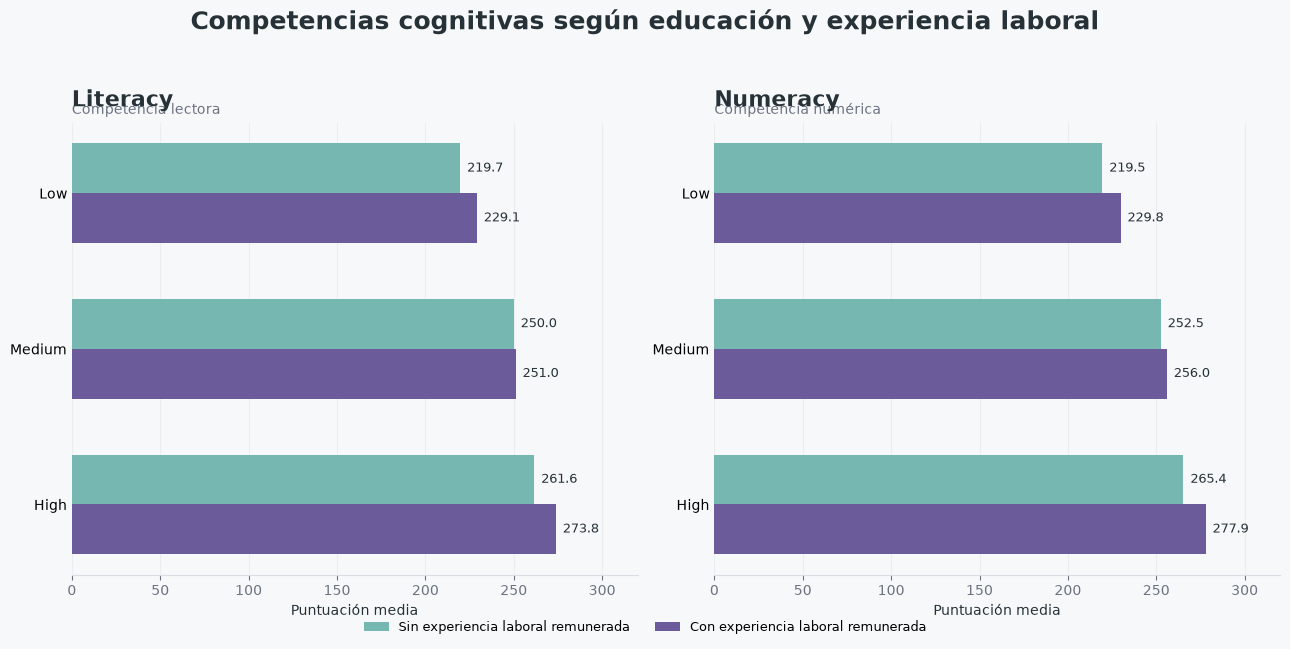

In [13]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Подготовка данных
education_order = ["Low", "Medium", "High"]

df_plot = (
    df_h3.groupby(["education_level", "PAIDWORK5"])[
        ["literacy_mean", "numeracy_mean"]
    ]
    .mean()
    .reset_index()
)

df_plot["PAIDWORK5"] = df_plot["PAIDWORK5"].astype(str)

# Современная палитра проекта
color_no_work = "#76B7B2"   # Teal
color_work = "#6C5B9A"      # Purple
background = "#F7F8FA"
text_color = "#263238"

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
fig.patch.set_facecolor(background)

skills = [
    ("literacy_mean", "Literacy", "Competencia lectora"),
    ("numeracy_mean", "Numeracy", "Competencia numérica")
]

y = np.arange(len(education_order))
bar_height = 0.32

for ax, (skill, title, subtitle) in zip(axes, skills):

    values_no_work = (
        df_plot[df_plot["PAIDWORK5"] == "0"]
        .set_index("education_level")
        .reindex(education_order)[skill]
    )

    values_work = (
        df_plot[df_plot["PAIDWORK5"] == "1"]
        .set_index("education_level")
        .reindex(education_order)[skill]
    )

    # Barras agrupadas
    bars_no_work = ax.barh(
        y - bar_height / 2,
        values_no_work,
        height=bar_height,
        color=color_no_work,
        label="Sin experiencia laboral remunerada"
    )

    bars_work = ax.barh(
        y + bar_height / 2,
        values_work,
        height=bar_height,
        color=color_work,
        label="Con experiencia laboral remunerada"
    )

    # Etiquetas directas de valores
    ax.bar_label(
        bars_no_work,
        fmt="%.1f",
        padding=5,
        fontsize=9,
        color=text_color
    )

    ax.bar_label(
        bars_work,
        fmt="%.1f",
        padding=5,
        fontsize=9,
        color=text_color
    )

    ax.set_yticks(y)
    ax.set_yticklabels(education_order, fontsize=10)
    ax.invert_yaxis()

    ax.set_title(
        title,
        fontsize=16,
        fontweight="bold",
        color=text_color,
        loc="left",
        pad=12
    )

    ax.text(
        0,
        1.02,
        subtitle,
        transform=ax.transAxes,
        fontsize=10,
        color="#6B7280"
    )

    ax.set_xlabel("Puntuación media", fontsize=10, color=text_color)
    ax.set_xlim(0, 320)

    # Diseño limpio
    ax.set_facecolor(background)
    ax.grid(axis="x", alpha=0.15, linestyle="-")
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_color("#D9DEE5")

    ax.tick_params(axis="y", length=0)
    ax.tick_params(axis="x", colors="#6B7280")

# Leyenda común
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=2,
    frameon=False,
    fontsize=9
)

fig.suptitle(
    "Competencias cognitivas según educación y experiencia laboral",
    fontsize=18,
    fontweight="bold",
    color=text_color,
    y=1.04
)

plt.tight_layout()
plt.show()


LIMITACIONES

### Limitaciones del análisis

- El análisis es observacional y no permite establecer relaciones causales.
- La variable PAIDWORK5 recoge la experiencia de trabajo remunerado durante los últimos cinco años, pero no aporta información detallada sobre la duración, intensidad o tipo de empleo.
- Las competencias cognitivas se representan mediante un indicador compuesto, calculado como la media de Literacy y Numeracy.
- El análisis no incorpora los pesos muestrales ni el diseño complejo de la encuesta PIAAC.
- Los resultados deben interpretarse como asociaciones exploratorias dentro de la población analizada en España.

### Paso 13 — Relación entre competencias cognitivas y experiencia laboral

**Objetivo:** explorar si las personas con mayores competencias cognitivas presentan una mayor proporción de experiencia laboral remunerada durante los últimos cinco años.

**¿Qué hacemos?**
- Dividimos la puntuación `cognitive_skills_mean` en cuatro cuartiles.
- Calculamos el porcentaje de personas con experiencia laboral remunerada (`PAIDWORK5 = 1`) en cada cuartil.
- Realizamos la comparación por nivel educativo (`EDLEVEL3`).

**¿Para qué?**
Explorar la relación entre las competencias cognitivas y la experiencia laboral, considerando el nivel educativo.

In [14]:
# Dividimos las competencias cognitivas en cuatro cuartiles

df_h3["cognitive_quartile"] = pd.qcut(
    df_h3["cognitive_skills_mean"].rank(method="first"),
    q=4,
    labels=["Q1 - Bajo", "Q2 - Medio-bajo", "Q3 - Medio-alto", "Q4 - Alto"]
)

# Calculamos el porcentaje de personas con experiencia laboral
# remunerada dentro de cada nivel educativo y cuartil cognitivo

employment_by_cognitive_quartile = pd.crosstab(
    [df_h3["education_level"], df_h3["cognitive_quartile"]],
    df_h3["PAIDWORK5"],
    normalize="index"
) * 100

# Mostramos únicamente el porcentaje con PAIDWORK5 = 1

employment_by_cognitive_quartile[["1"]].round(2)

PAIDWORK5                               1
education_level cognitive_quartile       
High            Q1 - Bajo           89.53
                Q2 - Medio-bajo     92.41
                Q3 - Medio-alto     93.32
                Q4 - Alto           95.50
Low             Q1 - Bajo           68.67
                Q2 - Medio-bajo     76.56
                Q3 - Medio-alto     76.34
                Q4 - Alto           77.10
Medium          Q1 - Bajo           77.01
                Q2 - Medio-bajo     81.48
                Q3 - Medio-alto     83.23
                Q4 - Alto           78.52

### Interpretación preliminar

Los resultados muestran una asociación positiva entre las competencias cognitivas y la proporción de personas con experiencia laboral remunerada en los últimos cinco años, especialmente entre las personas con nivel educativo alto.

En el grupo de nivel educativo bajo, la proporción aumenta de forma moderada. En el nivel educativo medio, se observa un incremento hasta el tercer cuartil, seguido de una disminución en el cuarto.

Estos resultados sugieren que la relación entre las competencias cognitivas y la experiencia laboral puede variar según el nivel educativo.

No obstante, se trata de un análisis descriptivo. No permite establecer causalidad ni confirmar la significación estadística de las diferencias.

In [15]:
print(employment_by_cognitive_quartile.columns)
print(employment_by_cognitive_quartile.head())

Index(['0', '1'], dtype='str', name='PAIDWORK5')
PAIDWORK5                                   0          1
education_level cognitive_quartile                      
High            Q1 - Bajo           10.471204  89.528796
                Q2 - Medio-bajo      7.586207  92.413793
                Q3 - Medio-alto      6.676783  93.323217
                Q4 - Alto            4.500549  95.499451
Low             Q1 - Bajo           31.332533  68.667467


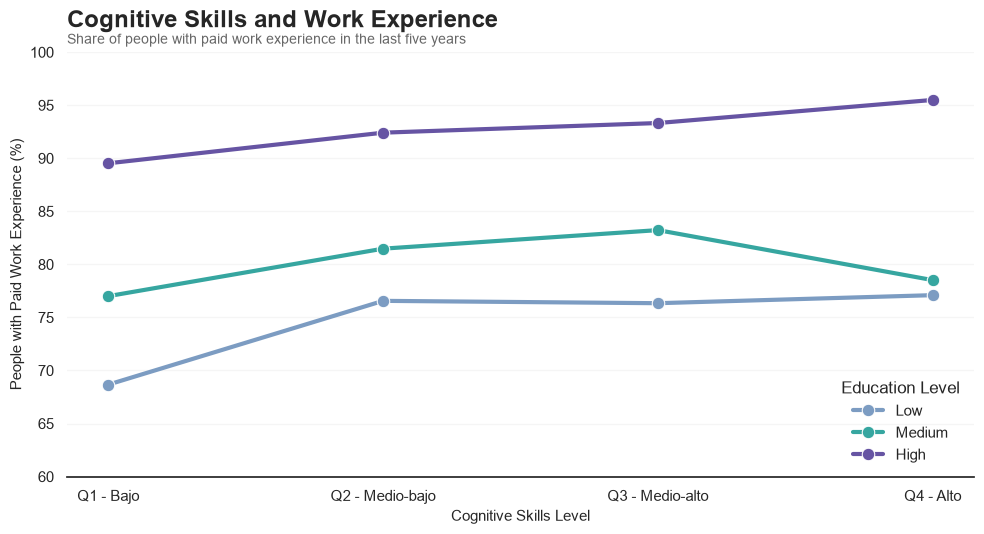

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Modern Data Storytelling style
sns.set_theme(style="white")

plot_data = employment_by_cognitive_quartile.reset_index()
plot_data = plot_data.rename(columns={"1": "employment_rate"})

palette = {
    "Low": "#7C9CC2",
    "Medium": "#36A6A0",
    "High": "#6654A3"
}

fig, ax = plt.subplots(figsize=(10, 5.5))

sns.lineplot(
    data=plot_data,
    x="cognitive_quartile",
    y="employment_rate",
    hue="education_level",
    hue_order=["Low", "Medium", "High"],
    palette=palette,
    marker="o",
    markersize=9,
    linewidth=3,
    ax=ax
)

ax.set_title(
    "Cognitive Skills and Work Experience",
    fontsize=17,
    fontweight="bold",
    loc="left",
    pad=18
)

ax.text(
    0,
    1.02,
    "Share of people with paid work experience in the last five years",
    transform=ax.transAxes,
    fontsize=10,
    color="#666666"
)

ax.set_xlabel("Cognitive Skills Level", fontsize=11)
ax.set_ylabel("People with Paid Work Experience (%)", fontsize=11)

ax.set_ylim(60, 100)

ax.legend(
    title="Education Level",
    frameon=False,
    loc="lower right"
)

ax.grid(axis="y", alpha=0.18)
ax.grid(axis="x", visible=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

plt.tight_layout()
plt.show()

### Prueba de Chi-cuadrado de independencia

Para analizar si existe una asociación entre las competencias cognitivas y la experiencia laboral remunerada, se aplica la prueba de Chi-cuadrado de independencia.

El análisis se realiza de forma separada para cada nivel educativo (Low, Medium y High), con el fin de observar si la relación entre las variables categóricas presenta diferencias según el nivel de educación.

La variable `cognitive_quartile` representa los cuartiles de competencias cognitivas, mientras que `PAIDWORK5` indica si la persona ha tenido experiencia laboral remunerada durante los últimos cinco años.

Se establece un nivel de significación de α = 0,05. Si el p-value es inferior a este umbral, se rechaza la hipótesis nula de independencia entre las variables.

La prueba permite identificar asociaciones estadísticas, pero no demuestra causalidad.

In [17]:
from scipy.stats import chi2_contingency
import pandas as pd

df_test = df_h3[
    df_h3["PAIDWORK5"].isin(["0", "1"])
].copy()

for level in ["Low", "Medium", "High"]:
    data_level = df_test[
        df_test["education_level"] == level
    ]

    contingency_table = pd.crosstab(
        data_level["cognitive_quartile"],
        data_level["PAIDWORK5"]
    )

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    print(f"\nNivel educativo: {level}")
    print(f"Chi-square: {chi2:.3f}")
    print(f"p-value: {p_value:.4f}")


Nivel educativo: Low
Chi-square: 14.097
p-value: 0.0028

Nivel educativo: Medium
Chi-square: 4.450
p-value: 0.2168

Nivel educativo: High
Chi-square: 12.032
p-value: 0.0073


### Análisis de la intensidad de la asociación: V de Cramér

Tras aplicar la prueba de Chi-cuadrado de independencia, se ha identificado una asociación estadísticamente significativa entre los cuartiles de competencias cognitivas y la experiencia laboral remunerada en los niveles educativos bajo y alto.

Sin embargo, la significación estadística no indica la intensidad de dicha asociación. Por este motivo, se calcula el V de Cramér, que permite evaluar la fuerza de la relación entre las variables categóricas.

Este análisis se realiza por separado para cada nivel educativo, con el objetivo de comparar la intensidad de la asociación.

In [18]:
# Importamos las librerías necesarias
import numpy as np
from scipy.stats import chi2_contingency

# Calculamos el V de Cramér para cada nivel educativo
for level in ["Low", "Medium", "High"]:

    # Filtramos los datos según el nivel educativo
    data_level = df_test[
        df_test["education_level"] == level
    ]

    # Creamos la tabla de contingencia
    contingency_table = pd.crosstab(
        data_level["cognitive_quartile"],
        data_level["PAIDWORK5"]
    )

    # Calculamos el estadístico Chi-cuadrado
    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    # Calculamos el tamaño de la muestra
    n = contingency_table.to_numpy().sum()

    # Calculamos V de Cramér
    min_dimension = min(contingency_table.shape) - 1
    cramer_v = np.sqrt(chi2 / (n * min_dimension))

    # Mostramos los resultados
    print(f"\nNivel educativo: {level}")
    print(f"Chi-square: {chi2:.3f}")
    print(f"p-value: {p_value:.4f}")
    print(f"Cramer's V: {cramer_v:.3f}")


Nivel educativo: Low
Chi-square: 14.097
p-value: 0.0028
Cramer's V: 0.089

Nivel educativo: Medium
Chi-square: 4.450
p-value: 0.2168
Cramer's V: 0.061

Nivel educativo: High
Chi-square: 12.032
p-value: 0.0073
Cramer's V: 0.074


### Interpretación de la intensidad de la asociación

Los valores de V de Cramér obtenidos son bajos en los tres niveles educativos, lo que indica una asociación de intensidad débil entre los cuartiles de competencias cognitivas y la experiencia laboral remunerada.

En el nivel educativo bajo (V = 0,089) y alto (V = 0,074), la asociación es estadísticamente significativa (p < 0,05), aunque su intensidad es reducida.

En el nivel educativo medio (V = 0,061), la asociación no resulta estadísticamente significativa (p = 0,2168).

En conjunto, los resultados sugieren que la relación entre las competencias cognitivas y la experiencia laboral remunerada es débil y presenta diferencias según el nivel educativo.

La significación estadística debe interpretarse junto con la intensidad de la asociación y el carácter exploratorio del análisis.

### Modelo de regresión logística

Para profundizar en la relación entre las competencias cognitivas y la experiencia laboral remunerada, se aplica un modelo de regresión logística.

La variable dependiente es `PAIDWORK5`, que indica si la persona ha tenido experiencia laboral remunerada durante los últimos cinco años (1 = sí, 0 = no).

Como variables explicativas se utilizan `cognitive_skills_mean`, que representa el promedio de las competencias cognitivas en Literacy y Numeracy, y `education_level`, que representa el nivel educativo.

El objetivo es analizar si las competencias cognitivas están asociadas con la experiencia laboral remunerada, teniendo en cuenta el nivel educativo. El análisis es exploratorio y no permite establecer relaciones causales.

In [19]:
import statsmodels.formula.api as smf

df_model = df_h3.copy()

# Переводим PAIDWORK5 в числовой формат
df_model["PAIDWORK5"] = df_model["PAIDWORK5"].astype(int)

# Масштабируем когнитивные навыки: изменение на 10 баллов
df_model["cognitive_skills_10"] = (
    df_model["cognitive_skills_mean"] / 10
)

# Логистическая регрессия
model = smf.logit(
    "PAIDWORK5 ~ cognitive_skills_10 + C(education_level, Treatment(reference='Low'))",
    data=df_model
).fit()

print(model.summary())

Optimization terminated successfully.
         Current function value: 0.413332
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:              PAIDWORK5   No. Observations:                 5192
Model:                          Logit   Df Residuals:                     5188
Method:                           MLE   Df Model:                            3
Date:                Sun, 08 Nov 2026   Pseudo R-squ.:                 0.07988
Time:                        22:05:30   Log-Likelihood:                -2146.0
converged:                       True   LL-Null:                       -2332.3
Covariance Type:            nonrobust   LLR p-value:                 1.894e-80
                                                               coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------------------
Intercept       

Un aumento de 10 puntos en las competencias cognitivas se relaciona con un incremento aproximado del 5,2% en las odds de haber tenido experiencia laboral remunerada.

El nivel educativo también presenta una asociación importante: las personas con educación alta tienen unas odds de experiencia laboral remunerada aproximadamente 4,37 veces superiores a las personas con educación baja, manteniendo constantes las competencias cognitivas.

El modelo es estadísticamente significativo en conjunto (p < 0,001), aunque su capacidad explicativa es limitada (Pseudo R² = 0,0799).

Conclusión de H3: Los resultados apoyan parcialmente la hipótesis de que unas competencias cognitivas más altas se relacionan con mejores resultados laborales, incluso considerando la educación formal. La interpretación debe ser cautelosa, ya que PAIDWORK5 mide experiencia laboral remunerada durante los últimos cinco años, no la situación laboral actual. Además, los resultados muestran asociaciones y no relaciones causales.

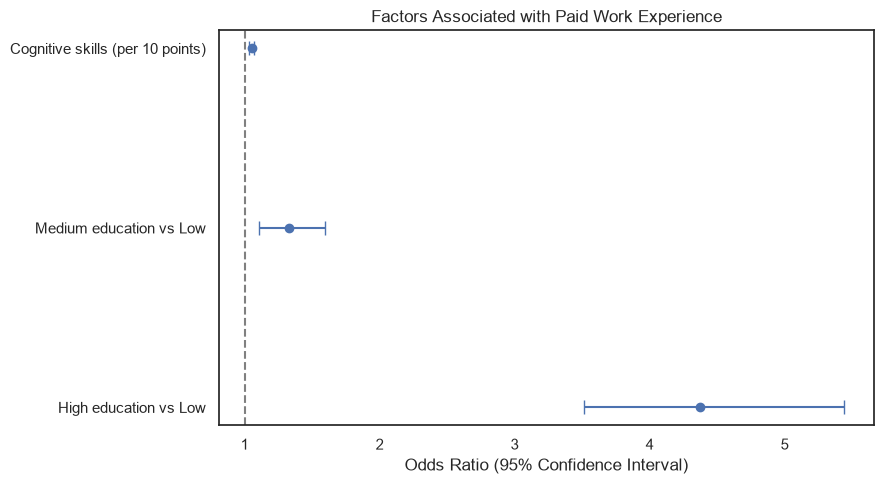

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# Coefficients and confidence intervals
params = model.params.drop("Intercept")
conf = model.conf_int().loc[params.index]

# Convert coefficients to Odds Ratios
or_values = np.exp(params)
ci_low = np.exp(conf[0])
ci_high = np.exp(conf[1])

# Labels for the chart
labels = {
    "cognitive_skills_10": "Cognitive skills (per 10 points)",
    "C(education_level, Treatment(reference='Low'))[T.Medium]": "Medium education vs Low",
    "C(education_level, Treatment(reference='Low'))[T.High]": "High education vs Low"
}

y = np.arange(len(params))

# Plot
plt.figure(figsize=(9, 5))

plt.errorbar(
    or_values,
    y,
    xerr=[or_values - ci_low, ci_high - or_values],
    fmt='o',
    capsize=5
)

plt.axvline(1, color='gray', linestyle='--')

plt.yticks(y, [labels.get(name, name) for name in params.index])
plt.xlabel("Odds Ratio (95% Confidence Interval)")
plt.title("Factors Associated with Paid Work Experience")
plt.tight_layout()
plt.show()

In [21]:

# Verificación de variables para ampliar el análisis H3

variables = [
    "C2_D10",
    "EARNMTHALLPPPC2",
    "ISCO08_C",
    "PAIDWORK5"
]

for variable in variables:
    print(f"\n--- {variable} ---")

    if variable in df.columns:
        print("Variable disponible")
        print("Valores y frecuencias:")
        display(df[variable].value_counts(dropna=False).head(15))
    else:
        print("Variable no disponible en el dataframe")



--- C2_D10 ---
Variable disponible
Valores y frecuencias:


C2_D10
1    3974
3     851
2     527
4     431
.      85
5       3
Name: count, dtype: int64


--- EARNMTHALLPPPC2 ---
Variable disponible
Valores y frecuencias:


EARNMTHALLPPPC2
.v                  2279
.                    260
2591.53290047449     101
2073.22632037959      96
2245.99518041123      79
4319.22150079082      73
2418.76404044286      70
1727.68860031633      68
3455.37720063266      57
3109.83948056939      56
2764.30176050613      54
2937.07062053776      42
1554.9197402847       39
1900.45746034796      38
1382.15088025306      34
Name: count, dtype: int64


--- ISCO08_C ---
Variable disponible
Valores y frecuencias:


ISCO08_C
9996    1813
4110     160
.         96
2221      95
4419      90
9112      83
5131      74
2330      70
9111      63
5120      62
5242      58
2341      58
5322      56
5132      55
1420      53
Name: count, dtype: int64


--- PAIDWORK5 ---
Variable disponible
Valores y frecuencias:


PAIDWORK5
1     4331
0      861
.u     595
.       84
Name: count, dtype: int64

### Conclusión de H3

La hipótesis H3 se confirma parcialmente.

El modelo de regresión logística muestra una asociación positiva y estadísticamente significativa entre las competencias cognitivas y la experiencia laboral remunerada durante los últimos cinco años, incluso teniendo en cuenta el nivel educativo. Un aumento de 10 puntos en las competencias cognitivas se relaciona con un incremento aproximado del 5,2% en las odds de haber tenido experiencia laboral remunerada.

El nivel educativo presenta una asociación más fuerte con el resultado laboral. Las personas con educación alta tienen unas odds aproximadamente 4,37 veces superiores a las personas con educación baja, manteniendo constantes las competencias cognitivas.

Sin embargo, el análisis por cuartiles muestra que la asociación entre las competencias cognitivas y la experiencia laboral es débil y no resulta estadísticamente significativa para el nivel educativo medio.

Por tanto, los resultados respaldan parcialmente la hipótesis inicial. Es importante señalar que PAIDWORK5 mide la experiencia laboral remunerada durante los últimos cinco años, no la situación laboral actual. Además, los datos son observacionales y no permiten establecer causalidad.

### Análisis exploratorio adicional – AI

**Pregunta de investigación:**

¿Las personas que trabajan en ocupaciones más expuestas a la inteligencia artificial presentan diferentes niveles de competencias cognitivas que las personas que trabajan en ocupaciones menos expuestas?

In [22]:
# Exploratory AI analysis: check compatibility between PIAAC and DAIOE

import pandas as pd

# Load DAIOE dataset
df_daioe = pd.read_excel("daioe_isco08.xlsx")

# Select the latest year available: 2025
df_daioe_2025 = df_daioe[
    df_daioe["year"] == 2025
].copy()

# Keep only the occupation code and AI exposure index
df_daioe_2025 = df_daioe_2025[
    ["occ_code_isco08", "occ_title_isco08", "daioe_allapps"]
].dropna(subset=["daioe_allapps"])

# Prepare occupation codes for merging
df_h3_ai = df_h3.copy()

df_h3_ai["ISCO08_C"] = pd.to_numeric(
    df_h3_ai["ISCO08_C"], errors="coerce"
)

df_daioe_2025["occ_code_isco08"] = pd.to_numeric(
    df_daioe_2025["occ_code_isco08"], errors="coerce"
)

# Remove invalid occupation codes
df_h3_ai = df_h3_ai[
    df_h3_ai["ISCO08_C"].notna() &
    (df_h3_ai["ISCO08_C"] != 9996)
].copy()

# Merge PIAAC with DAIOE
df_h3_ai = df_h3_ai.merge(
    df_daioe_2025,
    left_on="ISCO08_C",
    right_on="occ_code_isco08",
    how="left"
)

# Check matching results
total_records = len(df_h3_ai)
matched_records = df_h3_ai["daioe_allapps"].notna().sum()

print(f"Total valid PIAAC records: {total_records}")
print(f"Matched records: {matched_records}")
print(f"Unmatched records: {total_records - matched_records}")
print(f"Matching rate: {matched_records / total_records * 100:.2f}%")

# Check the matched occupations
display(
    df_h3_ai[
        ["ISCO08_C", "occ_title_isco08", "daioe_allapps"]
    ].drop_duplicates().head(20)
)

Total valid PIAAC records: 3915
Matched records: 3864
Unmatched records: 51
Matching rate: 98.70%


,ISCO08_C,occ_title_isco08,daioe_allapps
0,3332.0,Conference and event planners,29.990705
1,6112.0,Tree and shrub crop growers,26.292107
2,1120.0,Managing directors and chief executives,32.690926
3,7212.0,Welders and flamecutters,28.465250
4,3513.0,Computer network and systems technicians,44.877312
5,3334.0,Real estate agents and property managers,35.461727
6,5223.0,Shop sales assistants,28.313326
7,5221.0,Shopkeepers,30.452656
8,9621.0,"Messengers, package deliverers and luggage por...",24.691172
9,1439.0,Services managers not elsewhere classified,36.445950


In [23]:
# Análisis exploratorio de AI: comparación de competencias cognitivas según la exposición a AI

# Calcular la mediana del índice de exposición a AI
ai_exposure_median = df_daioe_2025["daioe_allapps"].median()

# Clasificar las ocupaciones en grupos de exposición baja y alta a AI
df_h3_ai["AI_exposure_group"] = df_h3_ai["daioe_allapps"].apply(
    lambda x: "Alta exposición a AI" if x >= ai_exposure_median
    else "Baja exposición a AI" if pd.notna(x)
    else "Desconocido"
)

# Conservar únicamente los registros con exposición a AI identificada
df_h3_ai_matched = df_h3_ai[
    df_h3_ai["AI_exposure_group"].isin(
        ["Baja exposición a AI", "Alta exposición a AI"]
    )
].copy()

# Comparar Literacy y Numeracy entre los grupos
ai_skills_comparison = (
    df_h3_ai_matched.groupby("AI_exposure_group")
    .agg(
        personas=("literacy_mean", "count"),
        literacy_mean=("literacy_mean", "mean"),
        numeracy_mean=("numeracy_mean", "mean")
    )
    .round(2)
)

display(ai_skills_comparison)

,personas,literacy_mean,numeracy_mean
AI_exposure_group,,,
Alta exposición a AI,1844,267.59,270.51
Baja exposición a AI,2020,246.47,249.91


In [24]:
# Comparar las competencias cognitivas según la exposición a AI
# y el nivel de educación formal

ai_education_comparison = (
    df_h3_ai_matched
    .groupby(["education_level", "AI_exposure_group"])
    .agg(
        personas=("literacy_mean", "count"),
        literacy_mean=("literacy_mean", "mean"),
        numeracy_mean=("numeracy_mean", "mean")
    )
    .round(2)
)

display(ai_education_comparison)

personas  literacy_mean  numeracy_mean
education_level AI_exposure_group                                           
High            Alta exposición a AI      1205         278.68         281.80
                Baja exposición a AI       695         267.06         272.22
Low             Alta exposición a AI       294         236.52         237.34
                Baja exposición a AI       814         228.91         229.48
Medium          Alta exposición a AI       345         255.35         259.33
                Baja exposición a AI       511         246.44         252.11

### Análisis exploratorio: competencias cognitivas según el nivel educativo y la exposición potencial a AI

Se utilizaron las variables `education_level`, `AI_exposure_group`, `literacy_mean` y `numeracy_mean` del conjunto `df_h3_ai_matched`.

Se agruparon las observaciones por nivel educativo y exposición potencial a AI para comparar el número de personas y las puntuaciones medias de Literacy y Numeracy.

Los resultados muestran que, dentro de los tres niveles educativos (Low, Medium y High), las personas que trabajan en ocupaciones con alta exposición potencial a AI presentan puntuaciones medias superiores en ambas competencias. Esta asociación es descriptiva y no implica causalidad.

In [25]:
# Comprobar la significación estadística de las diferencias
# en Literacy y Numeracy según la exposición a AI,
# dentro de cada nivel educativo

from scipy.stats import ttest_ind

resultados_ai = []

for nivel in ["Low", "Medium", "High"]:
    df_nivel = df_h3_ai_matched[
        df_h3_ai_matched["education_level"] == nivel
    ]

    grupo_alto = df_nivel[
        df_nivel["AI_exposure_group"] == "Alta exposición a AI"
    ]

    grupo_bajo = df_nivel[
        df_nivel["AI_exposure_group"] == "Baja exposición a AI"
    ]

    for variable in ["literacy_mean", "numeracy_mean"]:
        test = ttest_ind(
            grupo_alto[variable].dropna(),
            grupo_bajo[variable].dropna(),
            equal_var=False
        )

        diferencia = (
            grupo_alto[variable].mean()
            - grupo_bajo[variable].mean()
        )

        resultados_ai.append({
            "Nivel educativo": nivel,
            "Competencia": variable,
            "Diferencia de medias": round(diferencia, 2),
            "p-valor": round(test.pvalue, 4)
        })

df_resultados_ai = pd.DataFrame(resultados_ai)

display(df_resultados_ai)

,Nivel educativo,Competencia,Diferencia de medias,p-valor
0,Low,literacy_mean,7.61,0.0051
1,Low,numeracy_mean,7.86,0.0053
2,Medium,literacy_mean,8.92,0.0007
3,Medium,numeracy_mean,7.22,0.0089
4,High,literacy_mean,11.61,0.0000
5,High,numeracy_mean,9.58,0.0000


- Low (низкий уровень образования): Literacy — разница 7,61 балла, Numeracy — 7,86 балла.
- Medium (средний уровень): Literacy — 8,92 балла, Numeracy — 7,22 балла.
- High (высокий уровень): Literacy — 11,61 балла, Numeracy — 9,58 балла.
Все p-значения ниже 0,01. Это означает, что различия статистически значимы. В каждой образовательной группе работники профессий с высокой потенциальной экспозицией к AI имеют более высокие средние результаты Literacy и Numeracy.

Los resultados muestran diferencias estadísticamente significativas en las puntuaciones medias de Literacy y Numeracy entre los grupos de ocupaciones con alta y baja exposición potencial a AI, considerando los distintos niveles educativos.

Esta comparación exploratoria permite identificar una asociación entre las competencias cognitivas y la exposición potencial a AI de las ocupaciones. El índice DAIOE caracteriza las ocupaciones y no mide el efecto de la AI sobre las competencias individuales.

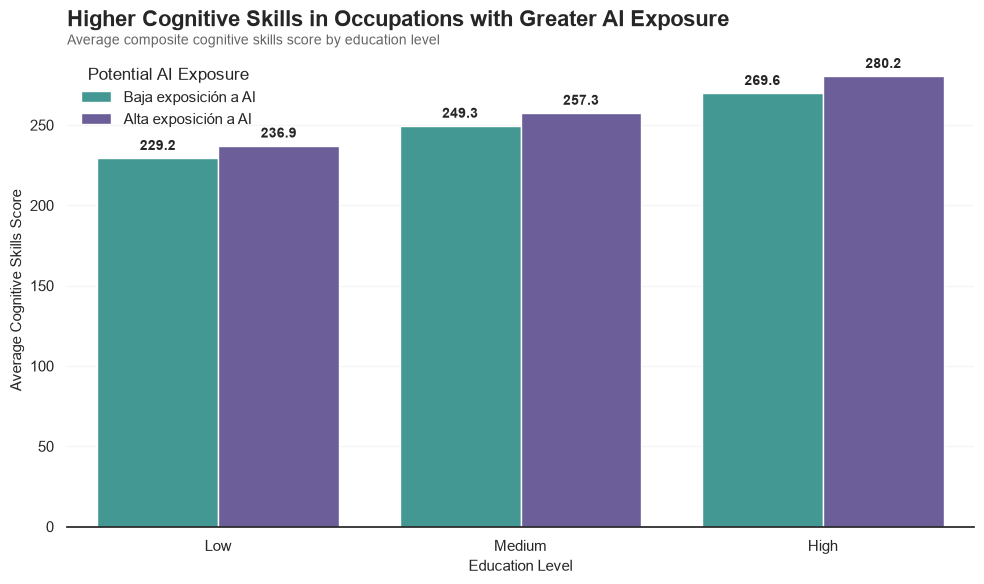

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# Estilo Modern Storytelling
sns.set_theme(style="white")

# Calculamos la media del indicador general de competencias cognitivas
# por nivel educativo y grupo de exposición potencial a AI

df_grafico_ai = (
    df_h3_ai_matched
    .groupby(["education_level", "AI_exposure_group"])["cognitive_skills_mean"]
    .mean()
    .reset_index()
)

# Orden de los niveles educativos
orden_educacion = ["Low", "Medium", "High"]

# Paleta visual
palette_ai = {
    "Baja exposición a AI": "#36A6A0",
    "Alta exposición a AI": "#6654A3"
}

# Crear gráfico
fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=df_grafico_ai,
    x="education_level",
    y="cognitive_skills_mean",
    hue="AI_exposure_group",
    order=orden_educacion,
    hue_order=["Baja exposición a AI", "Alta exposición a AI"],
    palette=palette_ai,
    errorbar=None,
    ax=ax
)

# Título y subtítulo
ax.set_title(
    "Higher Cognitive Skills in Occupations with Greater AI Exposure",
    fontsize=16,
    fontweight="bold",
    loc="left",
    pad=20
)

ax.text(
    0,
    1.02,
    "Average composite cognitive skills score by education level",
    transform=ax.transAxes,
    fontsize=10,
    color="#666666"
)

# Etiquetas
ax.set_xlabel("Education Level", fontsize=11)
ax.set_ylabel("Average Cognitive Skills Score", fontsize=11)

# Mostrar valores directamente sobre las barras
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f",
        padding=4,
        fontsize=10,
        fontweight="bold"
    )

# Ajustes visuales
ax.legend(
    title="Potential AI Exposure",
    frameon=False
)

ax.grid(axis="y", alpha=0.18)
ax.grid(axis="x", visible=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

plt.tight_layout()
plt.show()

### Conclusiones: competencias cognitivas y exposición potencial a la IA

El análisis muestra que, en los tres niveles educativos, los trabajadores de ocupaciones con una alta exposición potencial a la inteligencia artificial (IA) presentan una media de **Cognitive Skills Mean** superior a la de los trabajadores de ocupaciones con baja exposición.

La mayor diferencia se observa entre las personas con un nivel educativo alto. No obstante, esta diferencia positiva también se mantiene en los grupos con nivel educativo bajo y medio.

Estos resultados sugieren una asociación entre el nivel de competencias cognitivas y la exposición potencial de las ocupaciones a la IA. Sin embargo, no permiten afirmar que la IA requiera mayores competencias cognitivas ni que su uso aumente las habilidades de los trabajadores.

Los resultados deben interpretarse como una observación exploratoria, teniendo en cuenta que el índice de exposición a la IA describe las características de una ocupación y no el uso individual de la IA por parte de cada trabajador.

In [27]:
# Recalcular el test estadístico para Cognitive Skills Mean
# Comparación entre alta y baja exposición potencial a la IA
# Test: Welch's t-test

from scipy.stats import ttest_ind
import pandas as pd

results = []

for education in ["Low", "Medium", "High"]:

    group_high = df_h3_ai_matched[
        (df_h3_ai_matched["education_level"] == education) &
        (df_h3_ai_matched["AI_exposure_group"] == "Alta exposición a AI")
    ]["cognitive_skills_mean"].dropna()

    group_low = df_h3_ai_matched[
        (df_h3_ai_matched["education_level"] == education) &
        (df_h3_ai_matched["AI_exposure_group"] == "Baja exposición a AI")
    ]["cognitive_skills_mean"].dropna()

    t_stat, p_value = ttest_ind(
        group_high,
        group_low,
        equal_var=False
    )

    results.append({
        "Education Level": education,
        "N High Exposure": len(group_high),
        "N Low Exposure": len(group_low),
        "Mean High Exposure": group_high.mean(),
        "Mean Low Exposure": group_low.mean(),
        "Mean Difference": group_high.mean() - group_low.mean(),
        "t-statistic": t_stat,
        "p-value": p_value
    })

ttest_cognitive_skills = pd.DataFrame(results)

ttest_cognitive_skills.round(4)

,Education Level,N High Exposure,N Low Exposure,Mean High Exposure,Mean Low Exposure,Mean Difference,t-statistic,p-value
0,Low,294,814,236.9281,229.1945,7.7337,2.8879,0.004
1,Medium,345,511,257.3405,249.2731,8.0674,3.1000,0.002
2,High,1205,695,280.2395,269.6433,10.5962,5.9157,0.000


### Interpretación de los resultados del análisis de exposición potencial a la IA

Los resultados del test de Welch muestran diferencias estadísticamente significativas en el indicador compuesto *Cognitive Skills Mean* entre los grupos de alta y baja exposición potencial a la IA en los tres niveles educativos (p < 0.01).

En todos los niveles educativos, las ocupaciones con alta exposición potencial a la IA presentan una media de habilidades cognitivas superior a las ocupaciones con baja exposición. La diferencia más elevada se observa en el grupo con nivel educativo alto (+10.60 puntos), seguido del nivel medio (+8.07) y del nivel bajo (+7.73).

Estos resultados sugieren una asociación entre la exposición potencial de las ocupaciones a la IA y el nivel medio de habilidades cognitivas, considerando el nivel educativo. Sin embargo, no permiten establecer una relación causal.